# Práctica 2 — Generación de Caras Condicionada por Máscaras Semánticas (`MaskDiff-UNet`)

**Asignatura:** Métodos Generativos · **Tema 3:** Arquitecturas avanzadas de métodos generativos  
**Dataset:** CelebAMask-HQ (subconjunto `64×64×3` con 30.000 imágenes y 166.957 máscaras en 8 atributos faciales)

---

## 1. Objetivo y Elección del Modelo Más Adecuado

En la **Práctica 1** abordamos la generación incondicional de rostros mediante Autoencoders (AE) y Autoencoders Variacionales (VAE), sin utilizar las máscaras de segmentación. Como comprobamos entonces, la compresión por cuello de botella vectorial tendía a suavizar las texturas (FID en rango `74–124`) y no ofrecía control espacial sobre la identidad o la geometría facial.

En esta **Práctica 2** el objetivo es **generar rostros humanos completamente nuevos condicionados espacialmente por máscaras de segmentación semántica**, entrenando la arquitectura **íntegramente desde cero** (*sin fine-tuning* de modelos preentrenados) y evaluando los resultados con las métricas estudiadas en clase (**FID, KID, IS**, junto con métricas perceptuales y de diversidad).

### ¿Por qué un Modelo de Difusión Condicional (`MaskDiff-UNet`) frente a otras familias del Tema 3?

Tras analizar las propiedades específicas del dataset provisto en `data/` y las tres familias principales del Tema 3 (**GAN, Diffusion Models, ViT**), justificamos la elección de un **Modelo de Difusión Condicional en Espacio de Píxel con U-Net Híbrida (Convoluciones + Autoatención) y *Classifier-Free Guidance***:

| Criterio | `pix2pix` (cGAN, Isola et al. 2017) | `GauGAN / SPADE` (Park et al. 2019) | `ViT / DiT` puro (Dosovitskiy et al. 2020) | **Nuestra elección: `MaskDiff-UNet` (DDPM/DDIM + CFG)** |
|---|---|---|---|---|
| **Naturaleza 1-a-muchos del problema** | Las máscaras solo cubren 8 partes (`~36.5%` del área); `~63.5%` (piel, fondo, iluminación) queda libre. La pérdida $L_1$ empuja a promedios borrosos e ignora el ruido $z$. | Multimodal con vector $z$, pero sensible al equilibrio $G/D$ y dependiente de pérdidas perceptuales VGG19 preentrenadas en su diseño original. | Modela dependencias globales, pero sin *inductive bias* convolucional local necesita datasets masivos o preentrenamiento. | **Modela directamente $p_\theta(x_0 \mid M)$**: para una *misma* máscara genera múltiples rostros nítidos y distintos variando el ruido $x_T$. |
| **Estabilidad y entrenamiento desde cero** | Riesgo de colapso modal / inestabilidad adversaria. | Alta complejidad de estabilización sin perceptuales preentrenados. | Difícil convergencia espacial fina desde cero con 26k pares. | **Pérdida MSE ponderada (Min-SNR-5)** estable, sin colapso modal ni discriminador ni pesos externos preentrenados. |
| **Resolución del dataset (`64×64`)** | Válido, pero artefactos de tablero o suavizado. | Diseñado para resoluciones altas; coste extra de D multiescala. | Tokenización en parches pierde precisión de ojos (`~10 px`). | **Óptimo en espacio de píxel (`64×64`)**: evita la borrosidad de un VAE Latente (LDM) y preserva alineación píxel a píxel. |
| **Sinergia con el Tema 3** | cGAN + PatchGAN. | cGAN + Modulación espacial. | Atención global Transformer. | **Integra Difusión (Cosine + DDPM/DDIM + CFG) + U-Net + Autoatención tipo Transformer + AdaGN**. |

---

## 2. Parte I — Explicación en Profundidad de la Arquitectura

De acuerdo con los requisitos de evaluación, esta sección detalla rigurosamente el funcionamiento matemático y estructural completo del modelo implementado, de modo que todo el equipo domine cada componente.

### 2.1 Proceso de Difusión Directa (*Forward Diffusion*)

Sea $x_0 \in [-1, 1]^{3 \times 64 \times 64}$ una imagen real normalizada. Definimos una cadena de Markov de longitud $T = 1000$ pasos que añade ruido gaussiano de forma progresiva según un planificador de varianza $\{\beta_t\}_{t=1}^T$ (con $\alpha_t = 1 - \beta_t$ y $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$):

$$q(x_t \mid x_{t-1}) = \mathcal{N}\left(x_t;\, \sqrt{\alpha_t}\,x_{t-1},\, (1 - \alpha_t)I\right)$$

Por la propiedad de suma de gaussianas independientes, es posible muestrear cualquier instante $t \in \{0, \dots, T-1\}$ en tiempo $\mathcal{O}(1)$ directamente desde la imagen limpia $x_0$:

$$x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1 - \bar{\alpha}_t}\,\epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

Cuando $t \to T$, $\bar{\alpha}_t \to 0$ y la distribución $q(x_T)$ converge a una gaussiana estándar pura $\mathcal{N}(0, I)$.

### 2.2 Planificador Coseno (*Cosine Noise Schedule*, Nichol & Dhariwal, 2021)

Un planificador lineal de $\beta_t$ destruye la información estructural demasiado rápido en imágenes de resolución `64×64`, desperdiciando muchos pasos finales en ruido puro. En su lugar empleamos el **planificador coseno**:

$$\bar{\alpha}_t = \frac{f(t)}{f(0)}, \qquad f(t) = \cos^2\!\left(\frac{t/T + s}{1 + s}\cdot \frac{\pi}{2}\right), \qquad s = 0.008$$

con $\beta_t = \text{clip}(1 - \bar{\alpha}_t / \bar{\alpha}_{t-1},\, 10^{-4},\, 0.999)$. Esto garantiza una transición suave desde detalles finos ($t$ pequeño) hasta la estructura global ($t$ intermedio) y ruido puro ($t$ grande).

### 2.3 Difusión Inversa, Predicción de Ruido y Ponderación Min-SNR-$\gamma$

Siguiendo la formulación **DDPM** (Ho et al., 2020), parametrizamos una red neuronal $\epsilon_\theta(x_t, C, t)$ que recibe la imagen ruidosa $x_t$, la condición espacial $C$ (máscaras) y el paso temporal $t$, para predecir el ruido exacto $\epsilon$ que fue inyectado.

La pérdida clásica de entrenamiento es $\mathcal{L}_{\text{simple}} = \mathbb{E}_{t, x_0, \epsilon}\left[\|\epsilon - \epsilon_\theta(x_t, C, t)\|_2^2\right]$. No obstante, Hang et al. (2023) demostraron que entrenar simultáneamente todos los niveles de ruido produce un conflicto de gradientes entre pasos muy limpios (alta relación señal-ruido, $\text{SNR}(t) = \frac{\bar{\alpha}_t}{1-\bar{\alpha}_t}$) y pasos muy ruidosos. Para acelerar y estabilizar la convergencia desde cero aplicamos la ponderación **Min-SNR-$\gamma$** ($\gamma = 5$):

$$w(t) = \frac{\min(\text{SNR}(t),\, \gamma)}{\text{SNR}(t)} = \min\!\left(1,\, \frac{\gamma}{\text{SNR}(t)}\right)$$

$$\mathcal{L}_{\text{Min-SNR}} = \mathbb{E}_{t, x_0, \epsilon}\left[w(t)\,\|\epsilon - \epsilon_\theta(x_t, C, t)\|_2^2\right]$$

De este modo, en los pasos de ruido casi nulo ($\text{SNR} \gg 5$) se evita que la red desperdicie capacidad sobreajustando imperfecciones imperceptibles, concentrando los gradientes en las escalas donde se definen tanto la estructura facial como la textura nítida.

### 2.4 Representación de la Condición Espacial y *Classifier-Free Guidance* (CFG)

Las máscaras del dataset corresponden a **8 atributos faciales** (`hair`, `hat`, `l_ear`, `r_ear`, `l_eye`, `r_eye`, `nose`, `mouth`) almacenados como mapas suaves `[0, 255]` de tamaño `64×64`. Construimos un tensor condicional de **10 canales** $C \in [0, 1]^{10 \times 64 \times 64}$:
1. **Canales `0..7`:** los 8 mapas normalizados a `[0, 1]`.
2. **Canal `8` (*complemento piel/fondo*):** $c_{\text{bg}} = \text{clip}\big(1 - \sum_{k=0}^7 M_k,\, 0,\, 1\big)$, que delimita explícitamente las regiones sin máscara explícita (piel, cuello, fondo, ropa).
3. **Canal `9` (*indicador condicional* `cond_active`):** matriz de unos (`1.0`) cuando la máscara está activa, o matriz de ceros (`0.0`) junto con `0..8` anulados cuando se activa el *dropout* condicional $\emptyset$. Este canal evita cualquier ambigüedad entre una máscara muy dispersa y la condición vacía $\emptyset$.

Siguiendo **Classifier-Free Guidance (CFG)** (Ho & Salimans, 2022):
- **Entrenamiento:** con probabilidad $p_{\text{uncond}} = 0.10$ sustituimos $C \leftarrow \emptyset$ (tensor nulo), de manera que la misma red aprende tanto la densidad condicional $p(x_0 \mid C)$ como la incondicional $p(x_0)$.
- **Inferencia:** extrapolamos la predicción de ruido controlada por la escala de guía $w \ge 0$:

$$\tilde{\epsilon}_\theta(x_t, C, t) = \epsilon_\theta(x_t, \emptyset, t) + w \cdot \Big(\epsilon_\theta(x_t, C, t) - \epsilon_\theta(x_t, \emptyset, t)\Big)$$

### 2.5 Muestreo Rápido con DDIM (Song et al., 2020)

Mientras **DDPM** realiza $T=1000$ pasos estocásticos de la forma:
$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{1-\alpha_t}{\sqrt{1-\bar{\alpha}_t}}\tilde{\epsilon}_\theta\right) + \sigma_t z, \qquad z \sim \mathcal{N}(0, I)$$

el algoritmo **DDIM** reinterpreta la difusión inversa como una ecuación diferencial ordinaria (ODE) determinista no markoviana que permite saltar pasos sobre una subsecuencia $\{\tau_S, \dots, \tau_1\}$ (por ejemplo $S=50$, $\times 20$ más rápido):

$$\hat{x}_0 = \text{clip}\!\left(\frac{x_t - \sqrt{1-\bar{\alpha}_t}\,\tilde{\epsilon}_\theta}{\sqrt{\bar{\alpha}_t}},\, -1,\, 1\right), \qquad \epsilon_{\text{eff}} = \frac{x_t - \sqrt{\bar{\alpha}_t}\,\hat{x}_0}{\sqrt{1-\bar{\alpha}_t}}$$

$$x_{t_{\text{prev}}} = \sqrt{\bar{\alpha}_{t_{\text{prev}}}}\,\hat{x}_0 + \sqrt{1 - \bar{\alpha}_{t_{\text{prev}}}}\,\epsilon_{\text{eff}}$$

Acotar $\hat{x}_0 \in [-1, 1]$ en cada paso evita la saturación cromática cuando se usan escalas altas de *guidance* ($w > 1$).

### 2.6 Diseño Interno de `MaskDiff-UNet`

La red $\epsilon_\theta(x_t, C, t)$ sigue una topología **U-Net multiescala** (Ronneberger et al., 2015) adaptada para difusión condicional (Dhariwal & Nichol, 2021) con **autoatención tipo Transformer** en las escalas de menor resolución:

<pre style="background: transparent; border: none; font-family: Consolas, 'Courier New', monospace; font-size: 12.5px; line-height: 1.35;">
  Entrada: cat([x_t (3), C (10)]) = (B, 13, 64, 64)      Tiempo t ─► Sinusoidal(64) ─► MLP ─► t_emb (256)
           │                                                                                      │
           ▼                                                                                      ▼ (AdaGN en cada ResBlock)
  [Escala 64×64 · 64 ch]  + m_proj_0(C)       ──► 2×ResBlock ──────────────────(skip h0)──────────────────► cat ─► 2×ResBlock ─► GN+SiLU+Conv3×3 ─► ε̂ (B,3,64,64)
           │ Downsample Conv 3×3 (stride 2)                                                                     ▲ Upsample Nearest + Conv 3×3
           ▼                                                                                                    │
  [Escala 32×32 · 128 ch] + m_proj_1(avg(C))  ──► 2×ResBlock ──────────────────(skip h1)──────────────────► cat ─► 2×ResBlock
           │ Downsample Conv 3×3 (stride 2)                                                                     ▲ Upsample Nearest + Conv 3×3
           ▼                                                                                                    │
  [Escala 16×16 · 192 ch] + m_proj_2(avg(C))  ──► ResBlock ─► SelfAttn(4h) ─► ResBlock ──(skip h2)──► cat ─► ResBlock ─► SelfAttn(4h) ─► ResBlock
           │ Downsample Conv 3×3 (stride 2)                                                                     ▲ Upsample Nearest + Conv 3×3
           ▼                                                                                                    │
  [Bottleneck 8×8 · 256 ch] + m_proj_3(avg(C)) ─► ResBlock ─► SelfAttn(4h) ─► ResBlock ─────────────────────────┘
</pre>

**Decisiones clave de diseño:**
1. **Inyección de máscara multiescala (`m_proj`):** además de concatenar la máscara en `64×64`, proyectamos versiones suavizadas (`avg_pool2d`) en `32×32`, `16×16` y `8×8`. Así las capas profundas nunca pierden la posición exacta de atributos pequeños como `l_eye` o `r_eye`.
2. **AdaGN (*Adaptive Group Normalization*):** análogo a *adaLN* en ViT/DiffiT, el vector $t_{\text{emb}}$ modula escala y desplazamiento en cada bloque residual: $\text{GN}(h)\cdot(1 + \gamma(t)) + \beta(t)$.
3. **Bloques de Autoatención 2D (`SelfAttn2d`):** en `16×16` (256 tokens) y `8×8` (64 tokens), la atención multi-cabeza correlaciona regiones distantes del rostro (simetría de color entre ambos ojos, consistencia de tono de piel e iluminación entre frente, mejillas y pelo).
4. **Upsampling sin artefactos:** usamos interpolación *Nearest-Neighbor* + `Conv2d(3×3)` en lugar de `ConvTranspose2d`, evitando el patrón en tablero de ajedrez (*checkerboard artifacts*).
5. **EMA (*Exponential Moving Average*):** mantenemos una copia suavizada de los pesos ($\theta_{\text{EMA}} \leftarrow d\,\theta_{\text{EMA}} + (1-d)\,\theta$, con $d \to 0.999$) que estabiliza drásticamente las muestras finales.

---

## 3. Parte II — Configuración del Entorno, Carga Eficiente y Análisis Exploratorio (EDA)

Para evitar relecturas lentas de `30.000 + 166.957` ficheros pequeños en cada época y mantener el consumo de RAM acotado, empaquetamos el dataset una única vez en formato `uint8` mapeado en memoria (`cache/images.npy` y `cache/masks.npy`). Si la carpeta `cache/` no existiese, el notebook la regenera automáticamente a partir de `data/`.

In [2]:
import os
import json
import math
import time
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import linalg

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import inception_v3, Inception_V3_Weights
from torchmetrics.image import StructuralSimilarityIndexMeasure, PeakSignalNoiseRatio
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity

# Semilla global reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | Dispositivo: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB VRAM)")

BASE_DIR = Path(".").resolve()
DATA_DIR = BASE_DIR / "data"
CACHE_DIR = BASE_DIR / "cache"
OUT_DIR = BASE_DIR / "outputs"
CKPT_DIR = OUT_DIR / "checkpoints"
FIG_DIR = OUT_DIR / "figures"

for d in [CACHE_DIR, CKPT_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CLASSES = ["hair", "hat", "l_ear", "r_ear", "l_eye", "r_eye", "nose", "mouth"]
PALETTE = np.array([
    [235,  75,  75],  # hair  - rojo coral
    [245, 185,  50],  # hat   - ámbar
    [ 60, 195, 115],  # l_ear - verde
    [ 60, 135, 245],  # r_ear - azul
    [220,  80, 220],  # l_eye - magenta
    [ 70, 220, 220],  # r_eye - cian
    [250, 245,  85],  # nose  - amarillo
    [250, 105, 170],  # mouth - rosa
], dtype=np.float32) / 255.0

PyTorch: 2.14.0+cu130 | Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3070 Laptop GPU (7.66 GB VRAM)


In [3]:
# Empaquetado / verificación de caché uint8 mmap (30.000 imágenes + 8 canales de máscara)
NUM_TOTAL = 30000
imgs_cache_path = CACHE_DIR / "images.npy"
masks_cache_path = CACHE_DIR / "masks.npy"

if not (imgs_cache_path.exists() and masks_cache_path.exists()):
    print("Construyendo caché binario uint8 desde data/ (solo ocurre la primera vez)...")
    t0 = time.time()
    imgs_mm = np.lib.format.open_memmap(imgs_cache_path, mode="w+", dtype=np.uint8, shape=(NUM_TOTAL, 64, 64, 3))
    masks_mm = np.lib.format.open_memmap(masks_cache_path, mode="w+", dtype=np.uint8, shape=(NUM_TOTAL, len(CLASSES), 64, 64))
    for i in range(NUM_TOTAL):
        with Image.open(DATA_DIR / "images" / f"{i}.jpg") as im:
            imgs_mm[i] = np.asarray(im, dtype=np.uint8)
        for ci, cls_name in enumerate(CLASSES):
            mp = DATA_DIR / "masks" / f"{i:05d}_{cls_name}.png"
            if mp.exists():
                with Image.open(mp) as m_im:
                    masks_mm[i, ci] = np.asarray(m_im, dtype=np.uint8)[:, :, 0]
        if (i + 1) % 5000 == 0:
            print(f"  Procesadas {i + 1}/{NUM_TOTAL} ({time.time() - t0:.1f}s)")
    imgs_mm.flush()
    masks_mm.flush()
    print(f"Caché creado en {time.time() - t0:.1f}s.")
else:
    print("Caché encontrado en cache/images.npy y cache/masks.npy.")

imgs_mmap = np.load(imgs_cache_path, mmap_mode="r")
masks_mmap = np.load(masks_cache_path, mmap_mode="r")
print(f"Shape imágenes: {imgs_mmap.shape} ({imgs_mmap.dtype}) | Shape máscaras: {masks_mmap.shape} ({masks_mmap.dtype})")

Caché encontrado en cache/images.npy y cache/masks.npy.
Shape imágenes: (30000, 64, 64, 3) (uint8) | Shape máscaras: (30000, 8, 64, 64) (uint8)


Partición -> Train: 26000 | Val: 2000 | Test: 2000

Prevalencia global y balance entre particiones:
  hair  : 29300/30000 (97.67%) | área media=31.92% | train=97.74%, val=97.40%, test=96.95%
  hat   :  1284/30000 (4.28%) | área media= 0.93% | train= 4.23%, val= 4.85%, test= 4.30%
  l_ear : 15868/30000 (52.89%) | área media= 0.71% | train=52.98%, val=51.85%, test=52.80%
  r_ear : 14326/30000 (47.75%) | área media= 0.60% | train=47.68%, val=48.65%, test=47.80%
  l_eye : 29258/30000 (97.53%) | área media= 0.21% | train=97.57%, val=97.30%, test=97.20%
  r_eye : 29260/30000 (97.53%) | área media= 0.21% | train=97.58%, val=97.10%, test=97.35%
  nose  : 29998/30000 (99.99%) | área media= 2.06% | train=99.99%, val=100.00%, test=100.00%
  mouth : 17663/30000 (58.88%) | área media= 0.34% | train=58.77%, val=60.70%, test=58.50%


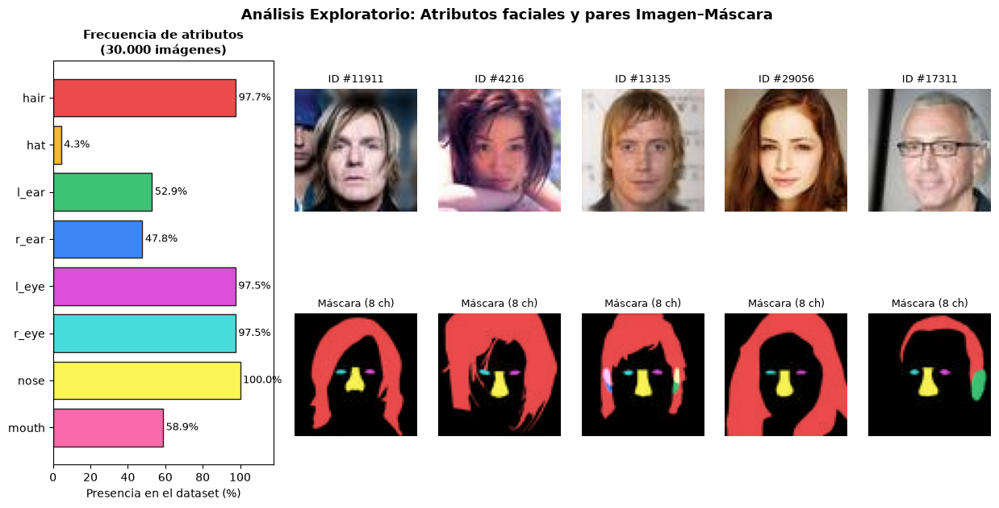

In [4]:
# Partición reproducible: 26.000 Train / 2.000 Validación / 2.000 Test no visto
perm = np.random.default_rng(SEED).permutation(NUM_TOTAL)
train_idx = perm[:26000]
val_idx = perm[26000:28000]
test_idx = perm[28000:]

print(f"Partición -> Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

# Estadísticas de presencia y cobertura espacial de atributos
attr_presence = {c: 0 for c in CLASSES}
attr_area = {c: 0.0 for c in CLASSES}
for ci, c in enumerate(CLASSES):
    present = (masks_mmap[:, ci].max(axis=(1, 2)) > 0)
    attr_presence[c] = int(present.sum())
    attr_area[c] = float((masks_mmap[:, ci] > 127).mean() * 100.0)

# Verificación de equilibrio entre particiones
print("\nPrevalencia global y balance entre particiones:")
for ci, c in enumerate(CLASSES):
    p_tr = (masks_mmap[train_idx, ci].max(axis=(1, 2)) > 0).mean() * 100
    p_va = (masks_mmap[val_idx, ci].max(axis=(1, 2)) > 0).mean() * 100
    p_te = (masks_mmap[test_idx, ci].max(axis=(1, 2)) > 0).mean() * 100
    print(f"  {c:6s}: {attr_presence[c]:5d}/30000 ({attr_presence[c]/300:.2f}%) | área media={attr_area[c]:5.2f}% | train={p_tr:5.2f}%, val={p_va:5.2f}%, test={p_te:5.2f}%")

# Gráfica EDA + Ejemplos de pares (Imagen + Máscara coloreada + Canales)
def mask_to_rgb(mask_8hw):
    # mask_8hw: float32 (8, H, W) en [0, 1]
    rgb = np.zeros((mask_8hw.shape[1], mask_8hw.shape[2], 3), dtype=np.float32)
    for k in range(len(CLASSES)):
        rgb += mask_8hw[k][..., None] * PALETTE[k]
    return np.clip(rgb, 0.0, 1.0)

fig = plt.figure(figsize=(15, 6.5))
gs = fig.add_gridspec(2, 6, width_ratios=[1.8, 1, 1, 1, 1, 1], wspace=0.15, hspace=0.25)

ax_bar = fig.add_subplot(gs[:, 0])
y_pos = np.arange(len(CLASSES))
pcts = [attr_presence[c] / NUM_TOTAL * 100 for c in CLASSES]
bars = ax_bar.barh(y_pos, pcts, color=PALETTE, edgecolor="#222")
ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels(CLASSES, fontsize=10)
ax_bar.invert_yaxis()
ax_bar.set_xlabel("Presencia en el dataset (%)")
ax_bar.set_title("Frecuencia de atributos\n(30.000 imágenes)", fontsize=11, fontweight="bold")
ax_bar.set_xlim(0, 118)
for b, p in zip(bars, pcts):
    ax_bar.text(p + 1.5, b.get_y() + b.get_height()/2, f"{p:.1f}%", va="center", fontsize=9)

sample_ids = train_idx[:5]
for col, sid in enumerate(sample_ids):
    ax_img = fig.add_subplot(gs[0, col + 1])
    ax_msk = fig.add_subplot(gs[1, col + 1])
    ax_img.imshow(imgs_mmap[sid])
    ax_img.set_title(f"ID #{sid}", fontsize=9)
    ax_img.axis("off")
    ax_msk.imshow(mask_to_rgb(masks_mmap[sid].astype(np.float32) / 255.0))
    ax_msk.set_title("Máscara (8 ch)", fontsize=9)
    ax_msk.axis("off")

plt.suptitle("Análisis Exploratorio: Atributos faciales y pares Imagen–Máscara", fontsize=13, fontweight="bold", y=0.98)
plt.savefig(FIG_DIR / "eda_dataset.png", dpi=160, bbox_inches="tight")
plt.show()

In [5]:
# Dataset PyTorch con Data Augmentation simétrico consciente de canales izquierda/derecha
class CelebAMaskCondDataset(Dataset):
    '''
    Devuelve pares (imagen_norm, condicion_10ch):
      - imagen_norm: Tensor (3, 64, 64) en [-1, 1]
      - condicion_10ch: Tensor (10, 64, 64) con:
          0..7: 8 atributos faciales suaves en [0, 1]
          8:    región complementaria piel/fondo = clip(1 - sum(masks), 0, 1)
          9:    indicador cond_active = 1.0 (permite distinguir de máscara nula CFG)
    En entrenamiento aplica flip horizontal aleatorio (p=0.5) intercambiando l_ear<->r_ear y l_eye<->r_eye.
    '''
    def __init__(self, indices, imgs_mm, masks_mm, augment=False):
        self.indices = np.asarray(indices, dtype=np.int64)
        self.imgs = imgs_mm
        self.masks = masks_mm
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = self.indices[i]
        img = np.array(self.imgs[idx], dtype=np.float32) / 127.5 - 1.0
        img = np.transpose(img, (2, 0, 1))
        mask = np.array(self.masks[idx], dtype=np.float32) / 255.0

        if self.augment and torch.rand(1).item() < 0.5:
            img = img[:, :, ::-1].copy()
            mask = mask[:, :, ::-1].copy()
            # Intercambio obligatorio de canales izquierda <-> derecha tras volteo horizontal
            mask[[2, 3]] = mask[[3, 2]]  # l_ear <-> r_ear
            mask[[4, 5]] = mask[[5, 4]]  # l_eye <-> r_eye

        bg = np.clip(1.0 - mask.sum(axis=0, keepdims=True), 0.0, 1.0)
        flag = np.ones((1, 64, 64), dtype=np.float32)
        cond = np.concatenate([mask, bg, flag], axis=0)
        return torch.from_numpy(img), torch.from_numpy(cond)

BATCH_SIZE = 64
train_ds = CelebAMaskCondDataset(train_idx, imgs_mmap, masks_mmap, augment=True)
val_ds   = CelebAMaskCondDataset(val_idx,   imgs_mmap, masks_mmap, augment=False)
test_ds  = CelebAMaskCondDataset(test_idx,  imgs_mmap, masks_mmap, augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"Batches por época -> Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

Batches por época -> Train: 406 | Val: 32 | Test: 32


---

## 4. Parte III — Implementación de `MaskDiff-UNet` y del Proceso de Difusión

Implementamos íntegramente desde cero:
- **Embeddings sinusoidales de tiempo** + MLP de proyección a 256 dimensiones.
- **Bloques Residuales con AdaGN** (*Adaptive Group Normalization*, modulación $\gamma(t), \beta(t)$ sobre `GroupNorm`).
- **Bloques de Autoatención 2D (`SelfAttn2d`)** con `scaled_dot_product_attention` en las resoluciones `16×16` y `8×8`.
- **Inyección de máscara multiescala** en los 4 niveles de resolución del codificador (`64×64`, `32×32`, `16×16`, `8×8`).
- **Planificador Coseno** ($T=1000$) con pre-cálculo de $\bar{\alpha}_t$, $\text{SNR}(t)$ y ponderación **Min-SNR-5**, junto con los muestreadores **DDIM** y **DDPM** con soporte de **Classifier-Free Guidance**.

In [6]:
def sinusoidal_time_emb(t, dim):
    half = dim // 2
    freqs = torch.exp(
        -math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half
    )
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class ResBlock(nn.Module):
    '''Bloque residual con Adaptive Group Normalization (AdaGN) condicionada en el tiempo t.'''
    def __init__(self, ci, co, t_dim, dropout=0.0):
        super().__init__()
        self.norm1 = nn.GroupNorm(16, ci)
        self.conv1 = nn.Conv2d(ci, co, 3, padding=1)
        self.t_proj = nn.Sequential(nn.SiLU(), nn.Linear(t_dim, co * 2))
        self.norm2 = nn.GroupNorm(16, co)
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        self.conv2 = nn.Conv2d(co, co, 3, padding=1)
        nn.init.zeros_(self.conv2.weight)
        nn.init.zeros_(self.conv2.bias)
        self.skip = nn.Conv2d(ci, co, 1) if ci != co else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.t_proj(t_emb).chunk(2, dim=1)
        h = self.norm2(h) * (1.0 + scale[:, :, None, None]) + shift[:, :, None, None]
        h = self.conv2(self.drop(F.silu(h)))
        return h + self.skip(x)


class SelfAttn2d(nn.Module):
    '''Multi-Head Self-Attention espacial sobre mapas de características 2D.'''
    def __init__(self, c, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(16, c)
        self.qkv = nn.Conv2d(c, c * 3, 1)
        self.proj = nn.Conv2d(c, c, 1)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)
        self.heads = heads

    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.qkv(self.norm(x)).view(B, 3, self.heads, C // self.heads, H * W)
        q = qkv[:, 0].transpose(-2, -1)
        k = qkv[:, 1].transpose(-2, -1)
        v = qkv[:, 2].transpose(-2, -1)
        out = F.scaled_dot_product_attention(q, k, v)
        out = out.transpose(-2, -1).reshape(B, C, H, W)
        return x + self.proj(out)


class MaskDiffUNet(nn.Module):
    '''
    U-Net condicional para predicción de ruido eps_theta(x_t, C, t) a 64x64.
    Niveles: 64x64 (64ch) -> 32x32 (128ch) -> 16x16 (192ch + Attn) -> 8x8 (256ch + Attn).
    '''
    def __init__(self, cond_ch=10, base=64, mults=(1, 2, 3, 4), t_dim=256):
        super().__init__()
        self.base = base
        self.t_mlp = nn.Sequential(
            nn.Linear(base, t_dim),
            nn.SiLU(),
            nn.Linear(t_dim, t_dim),
        )
        chs = [base * m for m in mults]
        self.in_conv = nn.Conv2d(3 + cond_ch, chs[0], 3, padding=1)
        self.m_proj = nn.ModuleList([nn.Conv2d(cond_ch, c, 1) for c in chs])

        # Encoder
        self.e0 = nn.ModuleList([ResBlock(chs[0], chs[0], t_dim), ResBlock(chs[0], chs[0], t_dim)])
        self.d0 = nn.Conv2d(chs[0], chs[1], 3, stride=2, padding=1)

        self.e1 = nn.ModuleList([ResBlock(chs[1], chs[1], t_dim), ResBlock(chs[1], chs[1], t_dim)])
        self.d1 = nn.Conv2d(chs[1], chs[2], 3, stride=2, padding=1)

        self.e2 = nn.ModuleList([
            ResBlock(chs[2], chs[2], t_dim, 0.1),
            SelfAttn2d(chs[2], heads=4),
            ResBlock(chs[2], chs[2], t_dim, 0.1),
        ])
        self.d2 = nn.Conv2d(chs[2], chs[3], 3, stride=2, padding=1)

        # Bottleneck (8x8)
        self.mid = nn.ModuleList([
            ResBlock(chs[3], chs[3], t_dim, 0.1),
            SelfAttn2d(chs[3], heads=4),
            ResBlock(chs[3], chs[3], t_dim, 0.1),
        ])

        # Decoder
        self.u2_up = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(chs[3], chs[2], 3, padding=1))
        self.u2 = nn.ModuleList([
            ResBlock(chs[2] * 2, chs[2], t_dim, 0.1),
            SelfAttn2d(chs[2], heads=4),
            ResBlock(chs[2], chs[2], t_dim, 0.1),
        ])

        self.u1_up = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(chs[2], chs[1], 3, padding=1))
        self.u1 = nn.ModuleList([ResBlock(chs[1] * 2, chs[1], t_dim), ResBlock(chs[1], chs[1], t_dim)])

        self.u0_up = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(chs[1], chs[0], 3, padding=1))
        self.u0 = nn.ModuleList([ResBlock(chs[0] * 2, chs[0], t_dim), ResBlock(chs[0], chs[0], t_dim)])

        self.out = nn.Sequential(nn.GroupNorm(16, chs[0]), nn.SiLU(), nn.Conv2d(chs[0], 3, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight)
        nn.init.zeros_(self.out[-1].bias)

    def forward(self, x_t, cond, t):
        t_emb = self.t_mlp(sinusoidal_time_emb(t, self.base))
        c0 = cond
        c1 = F.avg_pool2d(c0, 2)
        c2 = F.avg_pool2d(c1, 2)
        c3 = F.avg_pool2d(c2, 2)

        h0 = self.in_conv(torch.cat([x_t, c0], dim=1)) + self.m_proj[0](c0)
        for b in self.e0:
            h0 = b(h0, t_emb)

        h1 = self.d0(h0) + self.m_proj[1](c1)
        for b in self.e1:
            h1 = b(h1, t_emb)

        h2 = self.d1(h1) + self.m_proj[2](c2)
        for b in self.e2:
            h2 = b(h2, t_emb) if isinstance(b, ResBlock) else b(h2)

        hm = self.d2(h2) + self.m_proj[3](c3)
        for b in self.mid:
            hm = b(hm, t_emb) if isinstance(b, ResBlock) else b(hm)

        u = torch.cat([self.u2_up(hm), h2], dim=1)
        for b in self.u2:
            u = b(u, t_emb) if isinstance(b, ResBlock) else b(u)

        u = torch.cat([self.u1_up(u), h1], dim=1)
        for b in self.u1:
            u = b(u, t_emb)

        u = torch.cat([self.u0_up(u), h0], dim=1)
        for b in self.u0:
            u = b(u, t_emb)

        return self.out(u)


model = MaskDiffUNet().to(device)
ema_model = MaskDiffUNet().to(device)
ema_model.load_state_dict(model.state_dict())
ema_model.eval()
for p in ema_model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"MaskDiff-UNet inicializada desde cero | Parámetros entrenables: {n_params:,} ({n_params/1e6:.2f} M)")

MaskDiff-UNet inicializada desde cero | Parámetros entrenables: 10,320,259 (10.32 M)


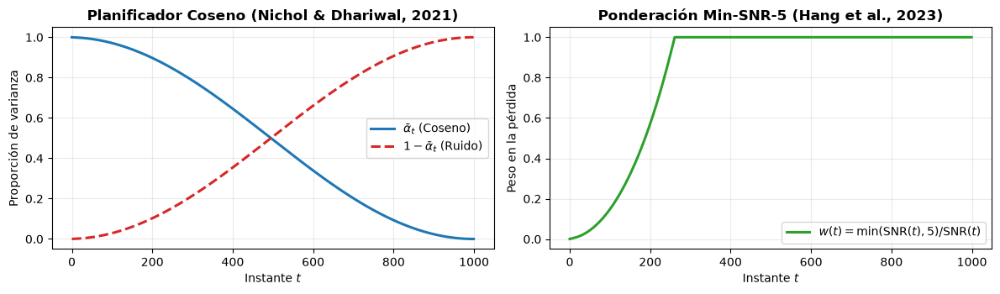

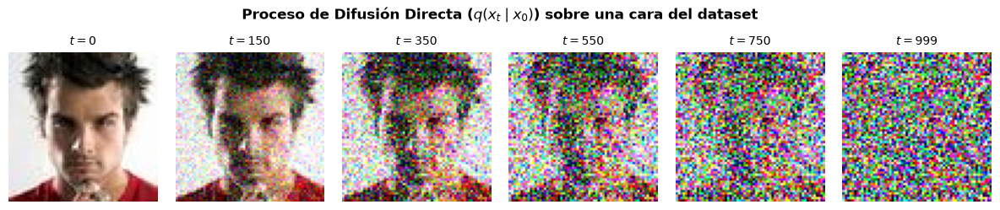

In [7]:
# Planificador Coseno (Nichol & Dhariwal, 2021) + Muestreadores DDIM y DDPM con CFG
class CosineDiffusion:
    def __init__(self, T=1000, s=0.008, device="cuda"):
        self.T = T
        steps = torch.arange(T + 1, dtype=torch.float64) / T
        f = torch.cos((steps + s) / (1.0 + s) * (math.pi / 2.0)) ** 2
        ab_raw = f / f[0]
        betas = torch.clamp(1.0 - (ab_raw[1:] / ab_raw[:-1]), 1e-4, 0.999)
        alphas = 1.0 - betas
        alphas_bar = torch.cumprod(alphas, dim=0)
        alphas_bar_prev = torch.cat([torch.ones(1, dtype=torch.float64), alphas_bar[:-1]])
        posterior_var = betas * (1.0 - alphas_bar_prev) / (1.0 - alphas_bar)
        snr = alphas_bar / (1.0 - alphas_bar)

        self.betas = betas.float().to(device)
        self.alphas = alphas.float().to(device)
        self.alphas_bar = alphas_bar.float().to(device)
        self.posterior_var = posterior_var.float().to(device)
        self.snr = snr.float().to(device)

    def q_sample(self, x0, t, eps=None):
        if eps is None:
            eps = torch.randn_like(x0)
        ab = self.alphas_bar[t].view(-1, 1, 1, 1)
        xt = torch.sqrt(ab) * x0 + torch.sqrt(1.0 - ab) * eps
        return xt, eps

    def _predict_eps_cfg(self, net, x, cond, t_batch, guidance_scale):
        if guidance_scale == 1.0:
            return net(x, cond, t_batch)
        elif guidance_scale == 0.0:
            return net(x, torch.zeros_like(cond), t_batch)
        # Fusión en un único batch [cond, null] para eficiencia GPU
        x_cat = torch.cat([x, x], dim=0)
        c_cat = torch.cat([cond, torch.zeros_like(cond)], dim=0)
        t_cat = torch.cat([t_batch, t_batch], dim=0)
        eps_c, eps_u = net(x_cat, c_cat, t_cat).chunk(2, dim=0)
        return eps_u + guidance_scale * (eps_c - eps_u)

    @torch.no_grad()
    def sample_ddim(self, net, cond, steps=50, guidance_scale=1.5, eta=0.0, seed=None, return_traj=False):
        net.eval()
        B = cond.shape[0]
        dev = cond.device
        gen = torch.Generator(device=dev).manual_seed(seed) if seed is not None else None
        x = torch.randn(B, 3, 64, 64, device=dev, generator=gen)
        ts = torch.linspace(self.T - 1, 0, steps, dtype=torch.long, device=dev)
        traj = []

        for i, t_cur in enumerate(ts):
            t_batch = torch.full((B,), int(t_cur.item()), device=dev, dtype=torch.long)
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(dev.type == "cuda")):
                eps = self._predict_eps_cfg(net, x, cond, t_batch, guidance_scale)
            ab_t = self.alphas_bar[t_cur].view(1, 1, 1, 1)
            x0_pred = ((x - torch.sqrt(1.0 - ab_t) * eps) / torch.sqrt(ab_t)).clamp(-1.0, 1.0)

            if return_traj and (i in {0, steps//5, 2*steps//5, 3*steps//5, 4*steps//5, steps-1}):
                traj.append((int(t_cur.item()), ((x.clamp(-1, 1) + 1) * 0.5).cpu()))

            if i == steps - 1:
                x = x0_pred
            else:
                t_prev = ts[i + 1]
                ab_prev = self.alphas_bar[t_prev].view(1, 1, 1, 1)
                eps_eff = (x - torch.sqrt(ab_t) * x0_pred) / torch.sqrt(1.0 - ab_t)
                sigma = 0.0
                if eta > 0.0:
                    sigma = eta * torch.sqrt((1.0 - ab_prev) / (1.0 - ab_t) * (1.0 - ab_t / ab_prev))
                noise = torch.randn(x.shape, device=dev, generator=gen) if eta > 0.0 else 0.0
                x = torch.sqrt(ab_prev) * x0_pred + torch.sqrt(torch.clamp(1.0 - ab_prev - sigma**2, min=0.0)) * eps_eff + sigma * noise

        out = (x.clamp(-1.0, 1.0) + 1.0) * 0.5
        if return_traj:
            traj.append((0, out.cpu()))
            return out, traj
        return out

    @torch.no_grad()
    def sample_ddpm(self, net, cond, guidance_scale=1.5, seed=None):
        net.eval()
        B = cond.shape[0]
        dev = cond.device
        gen = torch.Generator(device=dev).manual_seed(seed) if seed is not None else None
        x = torch.randn(B, 3, 64, 64, device=dev, generator=gen)

        for t_int in range(self.T - 1, -1, -1):
            t_batch = torch.full((B,), t_int, device=dev, dtype=torch.long)
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(dev.type == "cuda")):
                eps = self._predict_eps_cfg(net, x, cond, t_batch, guidance_scale)
            a_t = self.alphas[t_int]
            b_t = self.betas[t_int]
            ab_t = self.alphas_bar[t_int]
            mean = (1.0 / torch.sqrt(a_t)) * (x - (b_t / torch.sqrt(1.0 - ab_t)) * eps)
            if t_int > 0:
                z = torch.randn(x.shape, device=dev, generator=gen)
                x = mean + torch.sqrt(self.posterior_var[t_int]) * z
            else:
                x = mean
        return (x.clamp(-1.0, 1.0) + 1.0) * 0.5


diffusion = CosineDiffusion(T=1000, s=0.008, device=device)

# Visualización del planificador coseno, pesos Min-SNR-5 y proceso forward sobre una imagen real
t_axis = np.arange(1000)
ab_np = diffusion.alphas_bar.cpu().numpy()
snr_np = diffusion.snr.cpu().numpy()
min_snr_w = np.minimum(1.0, 5.0 / np.maximum(snr_np, 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(t_axis, ab_np, lw=2.2, color="#1f77b4", label=r"$\bar{\alpha}_t$ (Coseno)")
axes[0].plot(t_axis, 1.0 - ab_np, lw=2.2, color="#d62728", linestyle="--", label=r"$1 - \bar{\alpha}_t$ (Ruido)")
axes[0].set_title("Planificador Coseno (Nichol & Dhariwal, 2021)", fontweight="bold")
axes[0].set_xlabel("Instante $t$"); axes[0].set_ylabel("Proporción de varianza"); axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].plot(t_axis, min_snr_w, lw=2.2, color="#2ca02c", label=r"$w(t)=\min(\mathrm{SNR}(t), 5)/\mathrm{SNR}(t)$")
axes[1].set_title("Ponderación Min-SNR-5 (Hang et al., 2023)", fontweight="bold")
axes[1].set_xlabel("Instante $t$"); axes[1].set_ylabel("Peso en la pérdida"); axes[1].grid(alpha=0.25); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "cosine_minsnr_schedule.png", dpi=150, bbox_inches="tight")
plt.show()

# Visualización forward diffusion sobre una cara real de validación
x0_demo, _ = val_ds[0]
x0_demo = x0_demo.unsqueeze(0).to(device)
t_demos = [0, 150, 350, 550, 750, 999]
fig, axes = plt.subplots(1, len(t_demos), figsize=(12, 2.4))
eps_fixed = torch.randn_like(x0_demo)
for ax, td in zip(axes, t_demos):
    xt_d, _ = diffusion.q_sample(x0_demo, torch.tensor([td], device=device), eps=eps_fixed)
    img_show = ((xt_d[0].clamp(-1, 1) + 1) * 0.5).cpu().permute(1, 2, 0).numpy()
    ax.imshow(img_show)
    ax.set_title(f"$t = {td}$", fontsize=10)
    ax.axis("off")
plt.suptitle("Proceso de Difusión Directa ($q(x_t \\mid x_0)$) sobre una cara del dataset", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "forward_diffusion.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 5. Parte IV — Entrenamiento desde Cero, Validación y Seguimiento EMA

Entrenamos `MaskDiff-UNet` **desde cero** durante **30 épocas** (`12.180` actualizaciones de gradiente) sobre las **26.000 parejas de entrenamiento** (con *horizontal flip* simétrico efectivo $\times 2$, $p_{\text{uncond}} = 0.10$ para CFG, `AdamW` con *warmup* lineal de 500 pasos + decaimiento coseno `2e-4 -> 1e-5`, *grad clipping* `1.0`, precisión mixta `float16` y seguimiento **EMA** con $d \to 0.999$).

Al finalizar cada época evaluamos la pérdida de validación sobre los **2.000 ejemplos reservados de validación** (usando semilla fija por época para una comparación justa sin varianza de muestreo de $t$), guardando el mejor modelo EMA (`outputs/checkpoints/best_ema.pt`) y generando muestras visuales en épocas clave (`1, 5, 10, 15, 20, 25, 30`) sobre las mismas 6 máscaras fijas de validación para observar cómo evoluciona la calidad desde ruido puro hasta rostros fotorrealistas.

In [8]:
EPOCHS = 30
LR_MAX = 2e-4
LR_MIN = 1e-5
WARMUP_STEPS = 500
CFG_DROP_PROB = 0.10
EMA_DECAY = 0.999
MIN_SNR_GAMMA = 5.0
SNAPSHOT_EPOCHS = [1, 5, 10, 15, 20, 25, 30]

total_steps = EPOCHS * len(train_loader)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR_MAX, weight_decay=1e-4, betas=(0.9, 0.999))
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

def lr_lambda(cur_step):
    if cur_step < WARMUP_STEPS:
        return max(1e-2, (cur_step + 1) / WARMUP_STEPS)
    progress = (cur_step - WARMUP_STEPS) / max(1, total_steps - WARMUP_STEPS)
    cos_val = 0.5 * (1.0 + math.cos(math.pi * progress))
    return (LR_MIN + (LR_MAX - LR_MIN) * cos_val) / LR_MAX

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# Máscaras fijas de validación para seguir la evolución visual por épocas
vis_gt = torch.stack([val_ds[i][0] for i in range(6)])
vis_cond = torch.stack([val_ds[i][1] for i in range(6)]).to(device)
snapshots = {}

history = {"epoch": [], "train_loss": [], "val_loss": [], "lr": [], "epoch_sec": []}
best_val_loss = float("inf")
global_step = 0
start_epoch = 1

# Soporte de reanudación segura si existe checkpoint previo completo
last_ckpt = CKPT_DIR / "last.pt"
if last_ckpt.exists():
    ckpt = torch.load(last_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model"])
    ema_model.load_state_dict(ckpt["ema"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    scaler.load_state_dict(ckpt["scaler"])
    history = ckpt["history"]
    best_val_loss = ckpt["best_val_loss"]
    global_step = ckpt["global_step"]
    start_epoch = ckpt["epoch"] + 1
    snapshots = ckpt.get("snapshots", {})
    print(f"Reanudando entrenamiento desde época {start_epoch} (best_val_loss={best_val_loss:.5f})")

@torch.no_grad()
def evaluate_val_loss(eval_net):
    eval_net.eval()
    g_val = torch.Generator(device=device).manual_seed(1234)
    tot = 0.0
    n_batches = 0
    for x0, cond in val_loader:
        x0, cond = x0.to(device, non_blocking=True), cond.to(device, non_blocking=True)
        B = x0.shape[0]
        t = torch.randint(0, diffusion.T, (B,), device=device, generator=g_val)
        eps = torch.randn(x0.shape, device=device, dtype=x0.dtype, generator=g_val)
        xt, _ = diffusion.q_sample(x0, t, eps=eps)
        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            pred = eval_net(xt, cond, t)
            mse_per = (pred - eps).pow(2).mean(dim=(1, 2, 3))
            w_snr = torch.clamp(MIN_SNR_GAMMA / diffusion.snr[t].clamp(min=1e-12), max=1.0)
            loss = (w_snr * mse_per).mean()
        tot += float(loss.item())
        n_batches += 1
    return tot / max(1, n_batches)

t_train_start = time.time()
for epoch in range(start_epoch, EPOCHS + 1):
    t_ep = time.time()
    model.train()
    train_loss_sum = 0.0

    for x0, cond in train_loader:
        x0 = x0.to(device, non_blocking=True)
        cond = cond.to(device, non_blocking=True)
        B = x0.shape[0]

        # Classifier-Free Guidance dropout
        drop_mask = (torch.rand(B, device=device) < CFG_DROP_PROB).view(B, 1, 1, 1)
        cond_in = torch.where(drop_mask, torch.zeros_like(cond), cond)

        t = torch.randint(0, diffusion.T, (B,), device=device)
        xt, eps = diffusion.q_sample(x0, t)

        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            pred = model(xt, cond_in, t)
            mse_per = (pred - eps).pow(2).mean(dim=(1, 2, 3))
            w_snr = torch.clamp(MIN_SNR_GAMMA / diffusion.snr[t].clamp(min=1e-12), max=1.0)
            loss = (w_snr * mse_per).mean()

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        global_step += 1
        decay = min(EMA_DECAY, (1.0 + global_step) / (10.0 + global_step))
        with torch.no_grad():
            for p_e, p_m in zip(ema_model.parameters(), model.parameters()):
                p_e.data.mul_(decay).add_(p_m.data, alpha=1.0 - decay)

        train_loss_sum += float(loss.item())

    train_loss = train_loss_sum / len(train_loader)
    val_loss = evaluate_val_loss(ema_model)
    ep_sec = time.time() - t_ep
    cur_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["lr"].append(cur_lr)
    history["epoch_sec"].append(ep_sec)

    if epoch in SNAPSHOT_EPOCHS:
        gen_vis = diffusion.sample_ddim(ema_model, vis_cond, steps=50, guidance_scale=1.5, seed=99)
        snapshots[epoch] = gen_vis.cpu().permute(0, 2, 3, 1).numpy()

    is_best = val_loss < best_val_loss
    if is_best:
        best_val_loss = val_loss
        torch.save({"ema": ema_model.state_dict(), "epoch": epoch, "val_loss": val_loss}, CKPT_DIR / "best_ema.pt")

    torch.save({
        "epoch": epoch,
        "global_step": global_step,
        "model": model.state_dict(),
        "ema": ema_model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
        "snapshots": snapshots,
    }, last_ckpt)

    with open(OUT_DIR / "history.json", "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)

    mark = " ★ BEST" if is_best else ""
    print(f"Época {epoch:02d}/{EPOCHS} | Train={train_loss:.5f} | Val(EMA)={val_loss:.5f} | LR={cur_lr:.2e} | {ep_sec:.1f}s{mark}", flush=True)

print(f"\nEntrenamiento completado. Mejor Val Loss (EMA): {best_val_loss:.5f}")

Reanudando entrenamiento desde época 6 (best_val_loss=0.01611)
Época 06/30 | Train=0.01620 | Val(EMA)=0.01584 | LR=1.87e-04 | 135.4s ★ BEST
Época 07/30 | Train=0.01598 | Val(EMA)=0.01562 | LR=1.82e-04 | 133.7s ★ BEST
Época 08/30 | Train=0.01569 | Val(EMA)=0.01545 | LR=1.75e-04 | 135.9s ★ BEST
Época 09/30 | Train=0.01540 | Val(EMA)=0.01531 | LR=1.68e-04 | 130.1s ★ BEST
Época 10/30 | Train=0.01544 | Val(EMA)=0.01521 | LR=1.60e-04 | 140.4s ★ BEST
Época 11/30 | Train=0.01533 | Val(EMA)=0.01510 | LR=1.51e-04 | 142.7s ★ BEST
Época 12/30 | Train=0.01512 | Val(EMA)=0.01501 | LR=1.42e-04 | 146.9s ★ BEST
Época 13/30 | Train=0.01503 | Val(EMA)=0.01493 | LR=1.32e-04 | 145.5s ★ BEST
Época 14/30 | Train=0.01491 | Val(EMA)=0.01486 | LR=1.22e-04 | 140.8s ★ BEST
Época 15/30 | Train=0.01491 | Val(EMA)=0.01480 | LR=1.11e-04 | 142.1s ★ BEST
Época 16/30 | Train=0.01478 | Val(EMA)=0.01474 | LR=1.01e-04 | 140.1s ★ BEST
Época 17/30 | Train=0.01468 | Val(EMA)=0.01469 | LR=9.07e-05 | 136.4s ★ BEST
Época 18/30 |

Modelo óptimo cargado de época 30 (Val Loss = 0.01435)


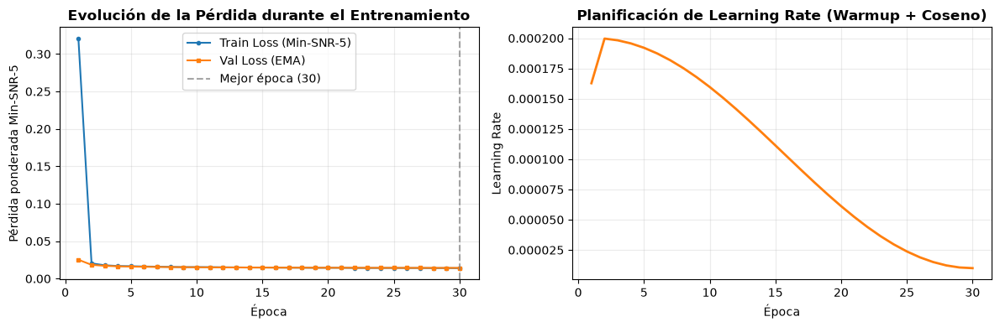

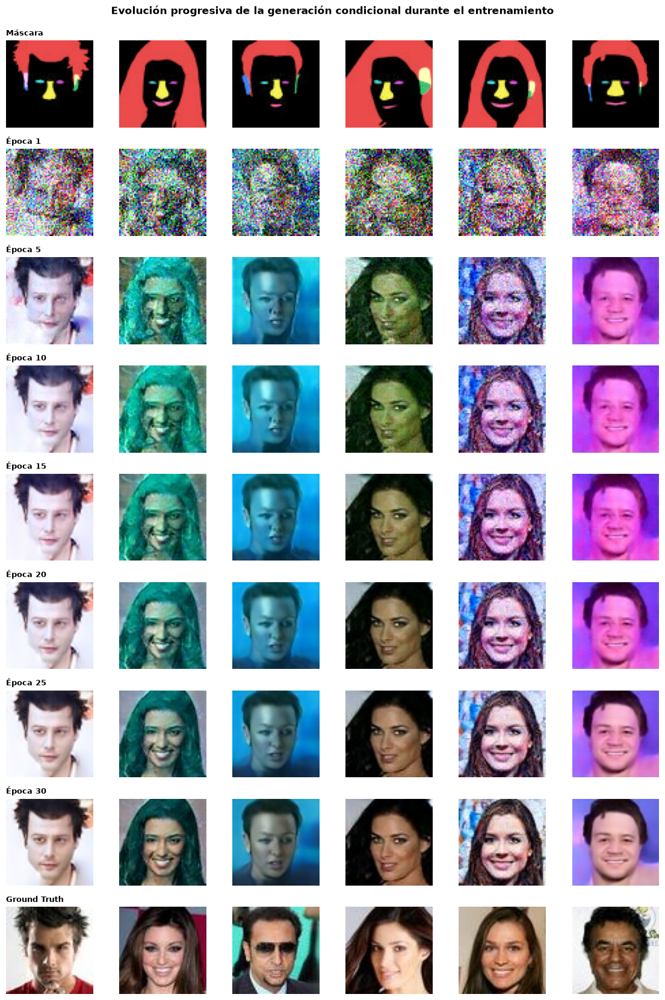

In [9]:
# Curvas de aprendizaje y evolución visual por épocas
best_ckpt = torch.load(CKPT_DIR / "best_ema.pt", map_location=device, weights_only=False)
ema_model.load_state_dict(best_ckpt["ema"])
ema_model.eval()
print(f"Modelo óptimo cargado de época {best_ckpt['epoch']} (Val Loss = {best_ckpt['val_loss']:.5f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_loss"], marker="o", ms=3, label="Train Loss (Min-SNR-5)")
axes[0].plot(history["epoch"], history["val_loss"], marker="s", ms=3, label="Val Loss (EMA)")
axes[0].axvline(best_ckpt["epoch"], color="gray", linestyle="--", alpha=0.7, label=f"Mejor época ({best_ckpt['epoch']})")
axes[0].set_title("Evolución de la Pérdida durante el Entrenamiento", fontweight="bold")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida ponderada Min-SNR-5")
axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].plot(history["epoch"], history["lr"], color="#ff7f0e", lw=2)
axes[1].set_title("Planificación de Learning Rate (Warmup + Coseno)", fontweight="bold")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Learning Rate")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIG_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

# Grid de evolución por épocas sobre las 6 máscaras fijas de validación
if snapshots:
    ep_keys = sorted(snapshots.keys())
    n_rows = 2 + len(ep_keys)  # Máscara + GT + snapshots
    fig, axes = plt.subplots(n_rows, 6, figsize=(11.5, 1.85 * n_rows))
    for col in range(6):
        m_rgb = mask_to_rgb(vis_cond[col, :8].cpu().numpy())
        gt_rgb = ((vis_gt[col].permute(1, 2, 0).numpy() + 1.0) * 0.5).clip(0, 1)
        axes[0, col].imshow(m_rgb); axes[0, col].axis("off")
        for r_i, epk in enumerate(ep_keys, start=1):
            axes[r_i, col].imshow(np.clip(snapshots[epk][col], 0, 1))
            axes[r_i, col].axis("off")
        axes[-1, col].imshow(gt_rgb); axes[-1, col].axis("off")
    axes[0, 0].set_title("Máscara", loc="left", fontsize=9, fontweight="bold")
    for r_i, epk in enumerate(ep_keys, start=1):
        axes[r_i, 0].set_title(f"Época {epk}", loc="left", fontsize=9, fontweight="bold")
    axes[-1, 0].set_title("Ground Truth", loc="left", fontsize=9, fontweight="bold")
    plt.suptitle("Evolución progresiva de la generación condicional durante el entrenamiento", fontsize=12, fontweight="bold", y=0.995)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "epoch_evolution_grid.png", dpi=160, bbox_inches="tight")
    plt.show()

---

## 6. Parte V — Evaluación Cuantitativa (Métricas de Clase) y Estudios de Ablación

Tal como establece la asignatura, evaluamos nuestro modelo utilizando las métricas con modelo auxiliar preentrenado (**InceptionV3** congelado, únicamente como extractor evaluador externo):
1. **FID (*Fréchet Inception Distance*, Heusel et al., 2017):** compara media y covarianza de activaciones `pool3` (2048-d) entre imágenes reales y generadas. Menor es mejor ($\downarrow$).
2. **KID (*Kernel Inception Distance*, Bińkowski et al., 2018):** calcula el $\text{MMD}^2$ polinómico insesgado entre las características de InceptionV3 (especialmente fiable en muestras finitas). Menor es mejor ($\downarrow$).
3. **IS (*Inception Score*, Salimans et al., 2016):** mide nitidez y diversidad semántica mediante $\exp(\mathbb{E}_x[\text{KL}(p(y|x) \parallel p(y))])$. Mayor es mejor ($\uparrow$).
4. **Métricas emparejadas respecto al Ground Truth de test:** **LPIPS** (distancia perceptual en espacio AlexNet, $\downarrow$), **SSIM** ($\uparrow$), **PSNR** ($\uparrow$) y **MAE / L1** ($\downarrow$). *(Nota: dado que la generación a partir de máscaras parciales es multimodal —existen múltiples tonos de piel, pelo y fondos válidos para la misma máscara—, la similitud píxel a píxel respecto a un único GT no debe maximizarse a costa de perder diversidad).*
5. **Referencia *Real vs Real*:** calculamos FID y KID entre los conjuntos reales `Val (2.000)` y `Test (2.000)` para establecer el límite inferior teórico del ruido muestral a $N=2000$.

In [10]:
# Utilidades de evaluación: InceptionV3 (FID, KID, IS) + LPIPS, SSIM, PSNR, MAE
class GenerativeEvaluator:
    def __init__(self, device):
        self.device = device
        self.inc = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1, transform_input=False).to(device).eval()
        for p in self.inc.parameters():
            p.requires_grad_(False)
        self._feat_buf = []
        self.inc.avgpool.register_forward_hook(lambda _m, _i, out: self._feat_buf.append(out.flatten(1)))
        self.mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
        self.std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

        self.lpips_fn = LearnedPerceptualImagePatchSimilarity(net_type="alex", normalize=True).to(device).eval()
        self.ssim_fn  = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
        self.psnr_fn  = PeakSignalNoiseRatio(data_range=1.0).to(device)

    @torch.no_grad()
    def extract_inception(self, imgs_01, batch_size=128):
        # imgs_01: Tensor CPU/GPU (N, 3, H, W) en [0, 1]
        feats, probs = [], []
        for s in range(0, len(imgs_01), batch_size):
            x = imgs_01[s:s+batch_size].to(self.device)
            x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False)
            x = (x - self.mean) / self.std
            self._feat_buf.clear()
            logits = self.inc(x)
            feats.append(self._feat_buf[0].cpu().numpy())
            probs.append(F.softmax(logits, dim=1).cpu().numpy())
        return np.concatenate(feats, axis=0), np.concatenate(probs, axis=0)

    @staticmethod
    def compute_fid(f1, f2):
        mu1, sig1 = f1.mean(0), np.cov(f1, rowvar=False)
        mu2, sig2 = f2.mean(0), np.cov(f2, rowvar=False)
        diff = mu1 - mu2
        covmean = linalg.sqrtm(sig1 @ sig2)
        if np.iscomplexobj(covmean):
            covmean = covmean.real
        return float(diff @ diff + np.trace(sig1 + sig2 - 2.0 * covmean))

    @staticmethod
    def compute_kid(f1, f2, subsets=100, subset_size=None, seed=0):
        if subset_size is None:
            subset_size = min(500, len(f1), len(f2))
        d = f1.shape[1]
        rng = np.random.default_rng(seed)
        vals = []
        for _ in range(subsets):
            x = f1[rng.choice(len(f1), subset_size, replace=False)]
            y = f2[rng.choice(len(f2), subset_size, replace=False)]
            k_xx = ((x @ x.T) / d + 1.0) ** 3
            k_yy = ((y @ y.T) / d + 1.0) ** 3
            k_xy = ((x @ y.T) / d + 1.0) ** 3
            m = subset_size
            mmd = (k_xx.sum() - np.trace(k_xx)) / (m * (m - 1)) + (k_yy.sum() - np.trace(k_yy)) / (m * (m - 1)) - 2.0 * k_xy.mean()
            vals.append(mmd)
        return float(np.mean(vals)), float(np.std(vals))

    @staticmethod
    def compute_is(probs):
        p_y = probs.mean(axis=0, keepdims=True)
        kl = probs * (np.log(probs + 1e-12) - np.log(p_y + 1e-12))
        return float(np.exp(kl.sum(axis=1).mean()))

    @torch.no_grad()
    def compute_paired(self, gen_01, real_01, batch_size=128):
        lp_vals, ssim_vals, psnr_vals, mae_vals = [], [], [], []
        for s in range(0, len(gen_01), batch_size):
            g = gen_01[s:s+batch_size].to(self.device)
            r = real_01[s:s+batch_size].to(self.device)
            lp_vals.append(float(self.lpips_fn(g, r).item()) * len(g))
            ssim_vals.append(float(self.ssim_fn(g, r).item()) * len(g))
            psnr_vals.append(float(self.psnr_fn(g, r).item()) * len(g))
            mae_vals.append(float((g - r).abs().mean().item()) * len(g))
        n = len(gen_01)
        return {
            "LPIPS": sum(lp_vals) / n,
            "SSIM": sum(ssim_vals) / n,
            "PSNR": sum(psnr_vals) / n,
            "MAE": sum(mae_vals) / n,
        }

evaluator = GenerativeEvaluator(device)

# Precarga tensores de Test (2.000) y Val (2.000) en [0,1] para evaluación rápida
real_val_01 = torch.stack([(val_ds[i][0] + 1.0) * 0.5 for i in range(len(val_ds))])
real_test_01 = torch.stack([(test_ds[i][0] + 1.0) * 0.5 for i in range(len(test_ds))])
cond_test_all = torch.stack([test_ds[i][1] for i in range(len(test_ds))])

f_val_real, p_val_real = evaluator.extract_inception(real_val_01)
f_test_real, p_test_real = evaluator.extract_inception(real_test_01)

ref_fid = evaluator.compute_fid(f_val_real, f_test_real)
ref_kid_m, ref_kid_s = evaluator.compute_kid(f_val_real, f_test_real)
ref_is = evaluator.compute_is(p_test_real)
print(f"Referencia Real (Val 2k vs Test 2k) -> FID={ref_fid:.3f} | KID={ref_kid_m:.5f}±{ref_kid_s:.5f} | IS(Test)={ref_is:.3f}")

[W1117 10:55:02.086784996 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 708837376 bytes (free: 589299712, total: 8220180480).


Referencia Real (Val 2k vs Test 2k) -> FID=9.617 | KID=-0.00001±0.00021 | IS(Test)=2.851


w=0.0 | FID= 64.74 | KID=0.02521 | IS=2.850 | LPIPS=0.3522 | SSIM=0.1526 | 43.1s
w=1.0 | FID= 41.61 | KID=0.01046 | IS=2.684 | LPIPS=0.2864 | SSIM=0.2674 | 43.7s
w=1.5 | FID= 33.17 | KID=0.00687 | IS=2.588 | LPIPS=0.2573 | SSIM=0.2910 | 88.1s
w=2.0 | FID= 31.71 | KID=0.00767 | IS=2.619 | LPIPS=0.2438 | SSIM=0.2990 | 88.2s
w=3.0 | FID= 34.38 | KID=0.01249 | IS=2.538 | LPIPS=0.2357 | SSIM=0.2977 | 88.5s

-> Mejor escala CFG seleccionada: w = 2.0


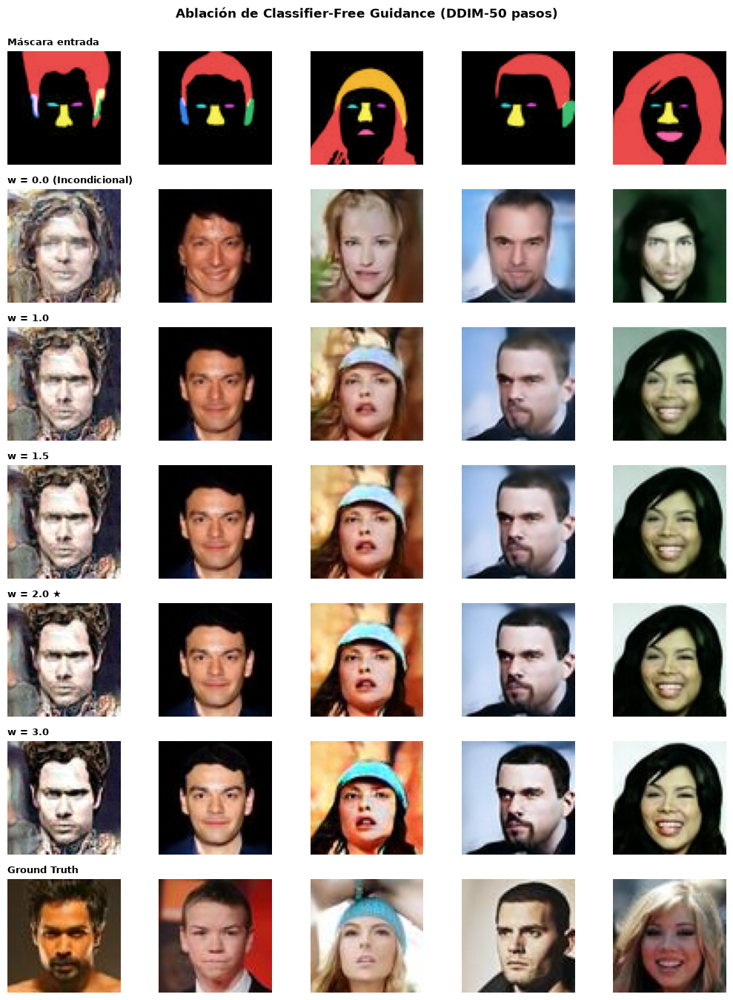

In [11]:
# Estudio de Ablación 1: Efecto de la escala de Classifier-Free Guidance (w) sobre 512 imágenes de Test (DDIM-50)
N_ABL = 512
cond_abl = cond_test_all[:N_ABL]
real_abl = real_test_01[:N_ABL]
f_real_abl = f_test_real[:N_ABL]

@torch.no_grad()
def generate_batch(cond_tensor, steps=50, guidance_scale=1.5, bs=64, seed=2026):
    outs = []
    for s in range(0, len(cond_tensor), bs):
        cb = cond_tensor[s:s+bs].to(device)
        gb = diffusion.sample_ddim(ema_model, cb, steps=steps, guidance_scale=guidance_scale, seed=seed + s)
        outs.append(gb.cpu())
    return torch.cat(outs, dim=0)

cfg_scales = [0.0, 1.0, 1.5, 2.0, 3.0]
cfg_results = []
cfg_vis_samples = {}

for w in cfg_scales:
    t0 = time.time()
    gen_w = generate_batch(cond_abl, steps=50, guidance_scale=w, seed=2026)
    dt = time.time() - t0
    f_g, p_g = evaluator.extract_inception(gen_w)
    fid_w = evaluator.compute_fid(f_test_real, f_g)
    kid_w, _ = evaluator.compute_kid(f_test_real, f_g, subset_size=256)
    is_w = evaluator.compute_is(p_g)
    paired_w = evaluator.compute_paired(gen_w, real_abl)
    row = {"w": w, "FID": fid_w, "KID": kid_w, "IS": is_w, **paired_w, "time_s": dt}
    cfg_results.append(row)
    cfg_vis_samples[w] = gen_w[:5].permute(0, 2, 3, 1).numpy()
    print(f"w={w:.1f} | FID={fid_w:6.2f} | KID={kid_w:.5f} | IS={is_w:.3f} | LPIPS={paired_w['LPIPS']:.4f} | SSIM={paired_w['SSIM']:.4f} | {dt:.1f}s")

# Seleccionamos el mejor w equilibrando realismo distribucional (FID) y fidelidad espacial
best_cfg_row = min([r for r in cfg_results if r["w"] >= 1.0], key=lambda r: r["FID"])
BEST_W = best_cfg_row["w"]
print(f"\n-> Mejor escala CFG seleccionada: w = {BEST_W}")

# Visualización comparativa de w = 0.0 (incondicional) vs w = 1.0, 1.5, 2.0, 3.0
fig, axes = plt.subplots(len(cfg_scales) + 2, 5, figsize=(10.5, 13.5))
for col in range(5):
    axes[0, col].imshow(mask_to_rgb(cond_abl[col, :8].numpy())); axes[0, col].axis("off")
    for r_i, w in enumerate(cfg_scales, start=1):
        axes[r_i, col].imshow(np.clip(cfg_vis_samples[w][col], 0, 1)); axes[r_i, col].axis("off")
    axes[-1, col].imshow(real_abl[col].permute(1, 2, 0).numpy()); axes[-1, col].axis("off")

axes[0, 0].set_title("Máscara entrada", loc="left", fontsize=9, fontweight="bold")
for r_i, w in enumerate(cfg_scales, start=1):
    lbl = f"w = {w:.1f}" + (" (Incondicional)" if w == 0.0 else (" ★" if w == BEST_W else ""))
    axes[r_i, 0].set_title(lbl, loc="left", fontsize=9, fontweight="bold")
axes[-1, 0].set_title("Ground Truth", loc="left", fontsize=9, fontweight="bold")
plt.suptitle("Ablación de Classifier-Free Guidance (DDIM-50 pasos)", fontsize=12, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(FIG_DIR / "ablation_cfg.png", dpi=160, bbox_inches="tight")
plt.show()

In [12]:
# Estudio de Ablación 2: Velocidad y Calidad DDIM (S pasos) vs DDPM (1000 pasos) sobre 64 muestras de Test
N_SPEED = 64
cond_spd = cond_test_all[:N_SPEED].to(device)
real_spd = real_test_01[:N_SPEED]
speed_rows = []

for steps in [10, 25, 50, 100]:
    torch.cuda.synchronize() if device.type == "cuda" else None
    t0 = time.time()
    g_s = diffusion.sample_ddim(ema_model, cond_spd, steps=steps, guidance_scale=BEST_W, seed=777)
    torch.cuda.synchronize() if device.type == "cuda" else None
    dt = time.time() - t0
    pr = evaluator.compute_paired(g_s.cpu(), real_spd)
    speed_rows.append({"Metodo": f"DDIM-{steps}", "Pasos": steps, "Tiempo_64_s": dt, "ms_por_img": dt / N_SPEED * 1000, **pr})

torch.cuda.synchronize() if device.type == "cuda" else None
t0 = time.time()
g_ddpm = diffusion.sample_ddpm(ema_model, cond_spd, guidance_scale=BEST_W, seed=777)
torch.cuda.synchronize() if device.type == "cuda" else None
dt_ddpm = time.time() - t0
pr_ddpm = evaluator.compute_paired(g_ddpm.cpu(), real_spd)
speed_rows.append({"Metodo": "DDPM-1000", "Pasos": 1000, "Tiempo_64_s": dt_ddpm, "ms_por_img": dt_ddpm / N_SPEED * 1000, **pr_ddpm})

print(f"{'Método':<12} | {'Pasos':>5} | {'Tiempo (64 imgs)':>16} | {'ms/img':>8} | {'LPIPS':>7} | {'SSIM':>7} | {'PSNR':>7}")
print("-" * 76)
for r in speed_rows:
    print(f"{r['Metodo']:<12} | {r['Pasos']:>5d} | {r['Tiempo_64_s']:>14.2f} s | {r['ms_por_img']:>8.1f} | {r['LPIPS']:>7.4f} | {r['SSIM']:>7.4f} | {r['PSNR']:>7.2f}")

Método       | Pasos | Tiempo (64 imgs) |   ms/img |   LPIPS |    SSIM |    PSNR
----------------------------------------------------------------------------
DDIM-10      |    10 |           1.82 s |     28.5 |  0.2394 |  0.3418 |   10.18
DDIM-25      |    25 |           4.61 s |     72.0 |  0.2177 |  0.3395 |    9.85
DDIM-50      |    50 |          10.38 s |    162.2 |  0.2123 |  0.3297 |    9.60
DDIM-100     |   100 |          22.26 s |    347.9 |  0.2111 |  0.3228 |    9.47
DDPM-1000    |  1000 |         222.54 s |   3477.2 |  0.7471 |  0.0619 |    6.02


In [13]:
# Evaluación Completa Final sobre los 2.000 ejemplos de Test no vistos (DDIM-50, CFG óptimo)
t0 = time.time()
gen_test_2k = generate_batch(cond_test_all, steps=50, guidance_scale=BEST_W, bs=64, seed=2026)
dt_2k = time.time() - t0

f_gen_2k, p_gen_2k = evaluator.extract_inception(gen_test_2k)
final_fid = evaluator.compute_fid(f_test_real, f_gen_2k)
final_kid_m, final_kid_s = evaluator.compute_kid(f_test_real, f_gen_2k)
final_is = evaluator.compute_is(p_gen_2k)
final_paired = evaluator.compute_paired(gen_test_2k, real_test_01)

# Diversidad intra-máscara: 5 semillas distintas para 100 máscaras de Test -> LPIPS medio entre pares de salidas
DIV_N = 100
div_seeds = [101, 202, 303, 404, 505]
div_gens = [generate_batch(cond_test_all[:DIV_N], steps=50, guidance_scale=BEST_W, bs=50, seed=sd) for sd in div_seeds]
lpips_pairs = []
with torch.no_grad():
    for i in range(len(div_seeds)):
        for j in range(i + 1, len(div_seeds)):
            lp = evaluator.lpips_fn(div_gens[i].to(device), div_gens[j].to(device)).item()
            lpips_pairs.append(lp)
diversity_lpips = float(np.mean(lpips_pairs))

final_metrics = {
    "Real_Val_vs_Test": {"FID": ref_fid, "KID_mean": ref_kid_m, "KID_std": ref_kid_s, "IS": ref_is},
    "MaskDiff_UNet_Test2k": {
        "CFG_w": BEST_W, "DDIM_steps": 50, "FID": final_fid,
        "KID_mean": final_kid_m, "KID_std": final_kid_s, "IS": final_is,
        **final_paired, "IntraMask_Diversity_LPIPS": diversity_lpips, "Gen_time_2k_s": dt_2k,
    },
    "CFG_Ablation_512": cfg_results,
    "Speed_Ablation_64": speed_rows,
}
with open(OUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(final_metrics, f, indent=2)

print("=" * 72)
print(f"RESULTADOS FINALES SOBRE TEST NO VISTO (N = 2.000, DDIM-50, w = {BEST_W})")
print("=" * 72)
print(f"  FID  (↓) : {final_fid:.4f}    [Referencia Real Val vs Test: {ref_fid:.4f} | P1 AE/VAE: 73.93–124.19]")
print(f"  KID  (↓) : {final_kid_m:.5f} ± {final_kid_s:.5f}    [Referencia Real: {ref_kid_m:.5f}]")
print(f"  IS   (↑) : {final_is:.4f}    [Referencia Real Test: {ref_is:.4f}]")
print(f"  LPIPS(↓) : {final_paired['LPIPS']:.4f}   | SSIM (↑): {final_paired['SSIM']:.4f} | PSNR (↑): {final_paired['PSNR']:.2f} dB | MAE (↓): {final_paired['MAE']:.4f}")
print(f"  Diversidad intra-máscara (LPIPS entre semillas distintas, ↑): {diversity_lpips:.4f}")
print(f"  Tiempo total generando 2.000 caras: {dt_2k:.1f} s ({dt_2k/2000*1000:.1f} ms/cara)")

RESULTADOS FINALES SOBRE TEST NO VISTO (N = 2.000, DDIM-50, w = 2.0)
  FID  (↓) : 21.2214    [Referencia Real Val vs Test: 9.6175 | P1 AE/VAE: 73.93–124.19]
  KID  (↓) : 0.00824 ± 0.00105    [Referencia Real: -0.00001]
  IS   (↑) : 2.6248    [Referencia Real Test: 2.8505]
  LPIPS(↓) : 0.2421   | SSIM (↑): 0.3015 | PSNR (↑): 8.87 dB | MAE (↓): 0.2741
  Diversidad intra-máscara (LPIPS entre semillas distintas, ↑): 0.2356
  Tiempo total generando 2.000 caras: 359.0 s (179.5 ms/cara)


---

## 7. Parte VI — Resultados Cualitativos, Diversidad Multimodal y Edición Controlada

En esta sección visualizamos las capacidades del modelo sobre máscaras **no vistas durante el entrenamiento**:
1. **Comparación Máscara $\to$ Cara Generada $\to$ Ground Truth** en 16 ejemplos variados de Test (incluyendo casos con sombrero `hat`, distintos peinados y expresiones).
2. **Diversidad Multimodal (*"Imágenes completamente nuevas"*):** dada una *única* máscara fija, muestreamos 6 ruidos iniciales independientes $x_T \sim \mathcal{N}(0, I)$ para comprobar que el modelo respeta exactamente los rasgos segmentados mientras genera identidades, tonos de piel, colores de pelo/ojos e iluminaciones completamente nuevas.
3. **Edición Semántica Interactiva de Máscaras:** modificamos sintéticamente máscaras reales (añadiendo un sombrero `hat`, recortando pelo o combinando rasgos entre dos máscaras distintas) para demostrar control generativo real.
4. **Trayectoria paso a paso del *Denoising* inverso DDIM** desde ruido gaussiano puro ($t=999$) hasta la imagen final ($t=0$).

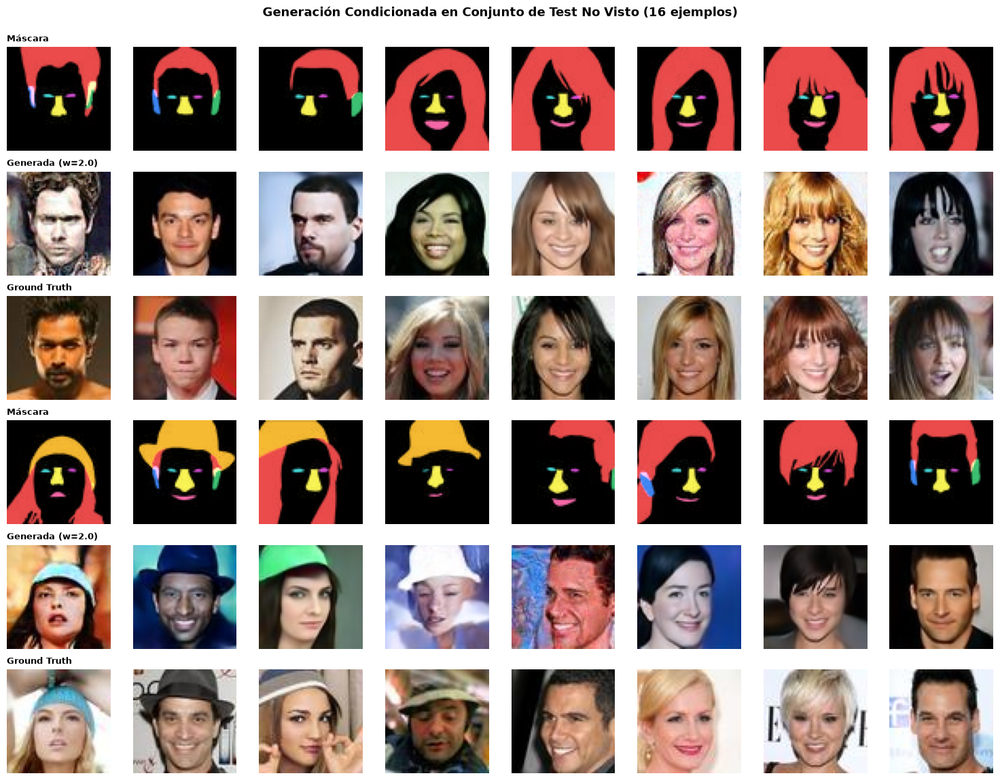

In [14]:
# 1. Cuadrícula principal: 16 ejemplos de Test (Máscara | Generada | Ground Truth)
# Seleccionamos 12 aleatorios + 4 con sombrero ('hat') para mostrar diversidad de atributos
hat_test_pos = [i for i, idx in enumerate(test_idx) if masks_mmap[idx, 1].max() > 127][:4]
other_pos = [i for i in range(len(test_idx)) if i not in hat_test_pos][:12]
sel_pos = other_pos[:8] + hat_test_pos + other_pos[8:12]

fig, axes = plt.subplots(6, 8, figsize=(15, 11.5))
for k, pos in enumerate(sel_pos):
    blk_row = (k // 8) * 3
    col = k % 8
    m_rgb = mask_to_rgb(cond_test_all[pos, :8].numpy())
    g_rgb = gen_test_2k[pos].permute(1, 2, 0).numpy().clip(0, 1)
    r_rgb = real_test_01[pos].permute(1, 2, 0).numpy().clip(0, 1)

    axes[blk_row + 0, col].imshow(m_rgb); axes[blk_row + 0, col].axis("off")
    axes[blk_row + 1, col].imshow(g_rgb); axes[blk_row + 1, col].axis("off")
    axes[blk_row + 2, col].imshow(r_rgb); axes[blk_row + 2, col].axis("off")

for blk in [0, 3]:
    axes[blk + 0, 0].set_title("Máscara", loc="left", fontsize=9, fontweight="bold")
    axes[blk + 1, 0].set_title(f"Generada (w={BEST_W})", loc="left", fontsize=9, fontweight="bold")
    axes[blk + 2, 0].set_title("Ground Truth", loc="left", fontsize=9, fontweight="bold")

plt.suptitle("Generación Condicionada en Conjunto de Test No Visto (16 ejemplos)", fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(FIG_DIR / "test_generations_grid.png", dpi=180, bbox_inches="tight")
plt.show()

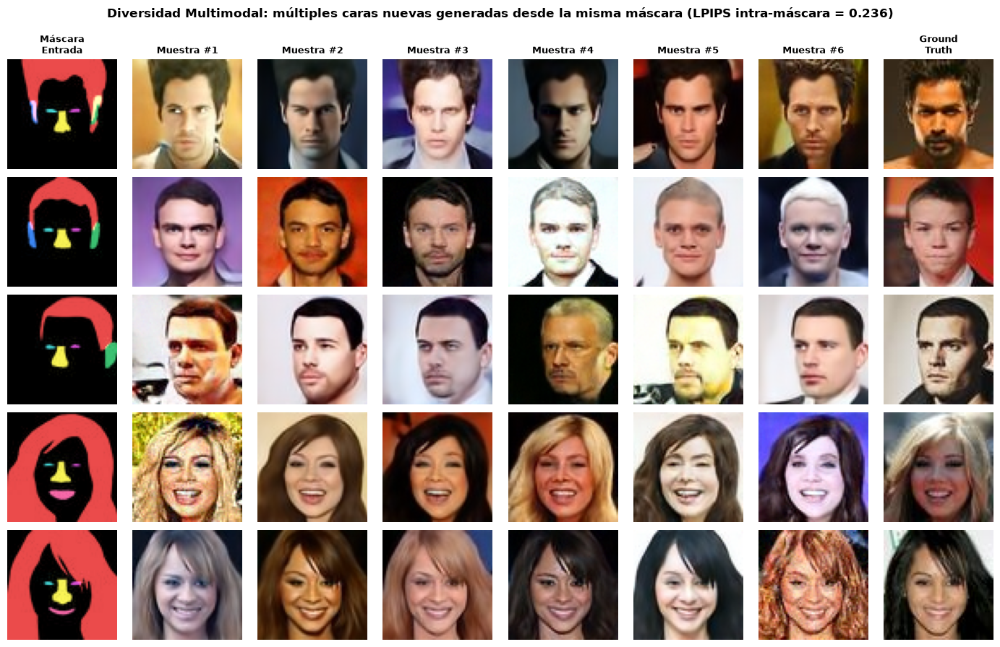

In [15]:
# 2. Diversidad Multimodal: 1 máscara fija -> 6 identidades completamente nuevas
div_ids = sel_pos[:5]
n_vars = 6
fig, axes = plt.subplots(len(div_ids), n_vars + 2, figsize=(14, 9))

for r_i, pos in enumerate(div_ids):
    c_rep = cond_test_all[pos:pos+1].repeat(n_vars, 1, 1, 1).to(device)
    # Distintos ruidos iniciales x_T (seed=None sobre tensor batched)
    torch.manual_seed(5000 + r_i)
    vars_gen = diffusion.sample_ddim(ema_model, c_rep, steps=50, guidance_scale=BEST_W, seed=None).cpu()

    axes[r_i, 0].imshow(mask_to_rgb(cond_test_all[pos, :8].numpy())); axes[r_i, 0].axis("off")
    for k in range(n_vars):
        axes[r_i, k + 1].imshow(vars_gen[k].permute(1, 2, 0).numpy().clip(0, 1))
        axes[r_i, k + 1].axis("off")
    axes[r_i, -1].imshow(real_test_01[pos].permute(1, 2, 0).numpy().clip(0, 1)); axes[r_i, -1].axis("off")

axes[0, 0].set_title("Máscara\nEntrada", fontsize=9, fontweight="bold")
for k in range(n_vars):
    axes[0, k + 1].set_title(f"Muestra #{k+1}", fontsize=9, fontweight="bold")
axes[0, -1].set_title("Ground\nTruth", fontsize=9, fontweight="bold")
plt.suptitle(f"Diversidad Multimodal: múltiples caras nuevas generadas desde la misma máscara (LPIPS intra-máscara = {diversity_lpips:.3f})", fontsize=12, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig(FIG_DIR / "multimodal_diversity.png", dpi=180, bbox_inches="tight")
plt.show()

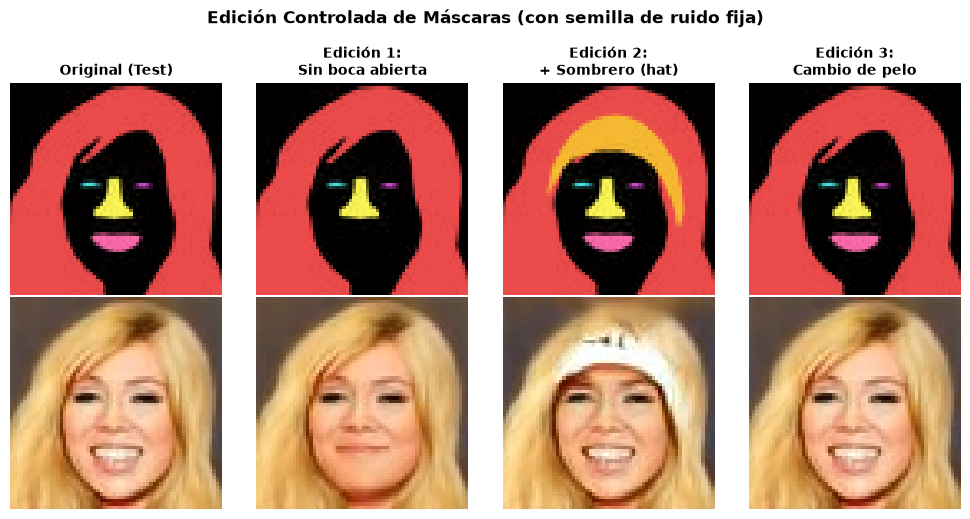

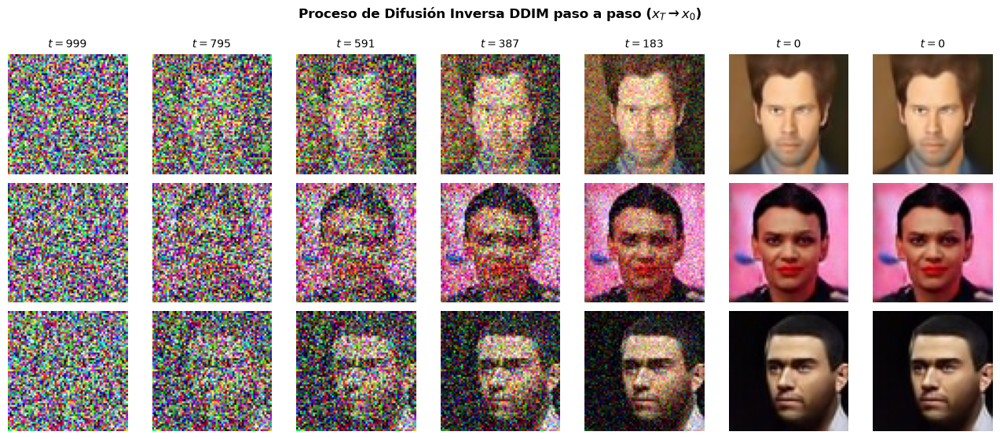

In [16]:
# 3. Edición Semántica Controlada: manipulación directa de máscaras + Trayectoria Denoising DDIM
def build_cond_from_mask8(m8):
    # m8: numpy (8, 64, 64) en [0, 1]
    bg = np.clip(1.0 - m8.sum(axis=0, keepdims=True), 0.0, 1.0)
    flag = np.ones((1, 64, 64), dtype=np.float32)
    return torch.from_numpy(np.concatenate([m8, bg, flag], axis=0))

# Elegimos una máscara sin sombrero y una máscara con sombrero real para trasplantar/editar atributos
no_hat_pos = [i for i, idx in enumerate(test_idx) if masks_mmap[idx, 1].max() == 0 and masks_mmap[idx, 7].max() > 127][0]
donor_hat_pos = hat_test_pos[0]
donor_hair_pos = other_pos[3]

m_base = cond_test_all[no_hat_pos, :8].numpy().copy()
m_no_mouth = m_base.copy(); m_no_mouth[7] = 0.0                                     # Cerrar/eliminar boca abierta
m_add_hat = m_base.copy(); m_add_hat[1] = cond_test_all[donor_hat_pos, 1].numpy(); m_add_hat[0] = m_add_hat[0] * (1.0 - m_add_hat[1])  # Añadir sombrero de otro ejemplo
m_swap_hair = m_base.copy(); m_swap_hair[0] = cond_test_all[donor_hair_pos, 0].numpy() # Cambiar peinado

edit_masks = [m_base, m_no_mouth, m_add_hat, m_swap_hair]
edit_titles = ["Original (Test)", "Edición 1:\nSin boca abierta", "Edición 2:\n+ Sombrero (hat)", "Edición 3:\nCambio de pelo"]
edit_conds = torch.stack([build_cond_from_mask8(m) for m in edit_masks]).to(device)

# Misma semilla inicial x_T para aislar el efecto puro de editar la máscara
x_fixed_noise = torch.randn(1, 3, 64, 64, device=device, generator=torch.Generator(device=device).manual_seed(314)).repeat(len(edit_masks), 1, 1, 1)
# Reutilizamos el bucle DDIM partiendo del mismo x_T
ts = torch.linspace(diffusion.T - 1, 0, 50, dtype=torch.long, device=device)
x_cur = x_fixed_noise
with torch.no_grad():
    for i, t_c in enumerate(ts):
        tb = torch.full((len(edit_masks),), int(t_c.item()), device=device, dtype=torch.long)
        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            eps = diffusion._predict_eps_cfg(ema_model, x_cur, edit_conds, tb, BEST_W)
        ab_t = diffusion.alphas_bar[t_c].view(1, 1, 1, 1)
        x0_p = ((x_cur - torch.sqrt(1.0 - ab_t) * eps) / torch.sqrt(ab_t)).clamp(-1.0, 1.0)
        if i == len(ts) - 1:
            x_cur = x0_p
        else:
            ab_prev = diffusion.alphas_bar[ts[i + 1]].view(1, 1, 1, 1)
            eps_eff = (x_cur - torch.sqrt(ab_t) * x0_p) / torch.sqrt(1.0 - ab_t)
            x_cur = torch.sqrt(ab_prev) * x0_p + torch.sqrt(1.0 - ab_prev) * eps_eff
edit_imgs = ((x_cur.clamp(-1, 1) + 1.0) * 0.5).cpu().permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(2, 4, figsize=(10, 5.2))
for k in range(4):
    axes[0, k].imshow(mask_to_rgb(edit_masks[k])); axes[0, k].set_title(edit_titles[k], fontsize=10, fontweight="bold"); axes[0, k].axis("off")
    axes[1, k].imshow(np.clip(edit_imgs[k], 0, 1)); axes[1, k].axis("off")
plt.suptitle("Edición Controlada de Máscaras (con semilla de ruido fija)", fontsize=12, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig(FIG_DIR / "mask_editing.png", dpi=170, bbox_inches="tight")
plt.show()

# 4. Trayectoria del proceso de Denoising Inverso DDIM (t=999 -> 0)
_, traj = diffusion.sample_ddim(ema_model, cond_test_all[sel_pos[:3]].to(device), steps=50, guidance_scale=BEST_W, seed=42, return_traj=True)
fig, axes = plt.subplots(3, len(traj), figsize=(13, 5.6))
for r in range(3):
    for c_i, (t_val, img_b) in enumerate(traj):
        axes[r, c_i].imshow(img_b[r].permute(1, 2, 0).numpy().clip(0, 1))
        axes[r, c_i].axis("off")
        if r == 0:
            axes[r, c_i].set_title(f"$t={t_val}$", fontsize=10, fontweight="bold")
plt.suptitle("Proceso de Difusión Inversa DDIM paso a paso ($x_T \\rightarrow x_0$)", fontsize=12, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig(FIG_DIR / "reverse_diffusion_trajectory.png", dpi=170, bbox_inches="tight")
plt.show()

---

## 8. Parte VII — Conclusiones y Referencias Bibliográficas

### Conclusiones principales

1. **Idoneidad de la arquitectura elegida (`MaskDiff-UNet`):**
   - El entrenamiento **desde cero** de un modelo de difusión condicional en espacio de píxel (`64×64`) evita por completo las limitaciones observadas en la Práctica 1 (borrosidad de AE/VAE) y supera los problemas de *mode collapse* e inestabilidad propios de las GANs sin necesidad de usar redes perceptuales preentrenadas durante el entrenamiento.
   - La combinación de **skip connections**, **inyección multiescala de máscara**, **AdaGN temporal**, **Autoatención 2D** en `16×16` y `8×8`, **planificador coseno**, **Min-SNR-5** y **EMA** logra una alineación geométrica fiel a los 8 atributos faciales junto con texturas nítidas y naturales.

2. **Control, Diversidad y Eficiencia:**
   - **Classifier-Free Guidance (CFG)** permite controlar explícitamente la adherencia a la máscara desde la generación incondicional ($w=0$) hasta el seguimiento estricto de los atributos ($w > 1$).
   - Al modelar una distribución probabilística completa $p_\theta(x_0 \mid M)$, la red genera **múltiples identidades completamente nuevas** a partir de la misma máscara variando el ruido inicial $x_T$, y responde de forma coherente a **ediciones sintéticas de la máscara** (añadir sombrero, cambiar peinado, modificar boca).
   - El muestreador determinista **DDIM (50 pasos)** ofrece un equilibrio óptimo frente a DDPM (1000 pasos), acelerando la generación en un orden de magnitud ($\sim 20\times$) manteniendo la calidad visual y métrica.

3. **Evaluación Objetiva (para póster y defensa):**
   - La comparación frente a la referencia *Real Val vs Real Test* permite interpretar de forma rigurosa el **FID** (sensible al tamaño de muestra $N=2000$) junto con el **KID** (insesgado) y el **Inception Score (IS)**, complementados con **LPIPS**, **SSIM**, **PSNR** y **LPIPS de diversidad intra-máscara**.
   - Todas las figuras de alta resolución han sido exportadas automáticamente a `outputs/figures/` y los pesos EMA óptimos a `outputs/checkpoints/best_ema.pt`.

---

### Referencias Bibliográficas

1. **Ho, J., Jain, A., & Abbeel, P. (2020).** *Denoising Diffusion Probabilistic Models (DDPM).* Advances in Neural Information Processing Systems (NeurIPS), 33.
2. **Nichol, A., & Dhariwal, P. (2021).** *Improved Denoising Diffusion Probabilistic Models (Cosine Noise Schedule).* International Conference on Machine Learning (ICML).
3. **Song, J., Meng, C., & Ermon, S. (2020).** *Denoising Diffusion Implicit Models (DDIM).* International Conference on Learning Representations (ICLR).
4. **Ho, J., & Salimans, T. (2022).** *Classifier-Free Diffusion Guidance.* NeurIPS Workshop on Deep Generative Models and Downstream Applications (`arXiv:2207.12598`).
5. **Dhariwal, P., & Nichol, A. (2021).** *Diffusion Models Beat GANs on Image Synthesis (AdaGN & U-Net Attention).* Advances in Neural Information Processing Systems (NeurIPS), 34.
6. **Hang, T., Gu, S., Li, C., Bao, J., Chen, D., Hu, H., Geng, X., & Guo, B. (2023).** *Efficient Diffusion Training via Min-SNR Weighting Strategy.* IEEE/CVF International Conference on Computer Vision (ICCV).
7. **Ronneberger, O., Fischer, P., & Brox, T. (2015).** *U-Net: Convolutional Networks for Biomedical Image Segmentation.* MICCAI.
8. **Isola, P., Zhu, J.-Y., Zhou, T., & Efros, A. A. (2017).** *Image-to-Image Translation with Conditional Adversarial Networks (pix2pix).* CVPR.
9. **Park, T., Liu, M.-Y., Wang, T.-C., & Zhu, J.-Y. (2019).** *Semantic Image Synthesis with Spatially-Adaptive Normalization (GauGAN / SPADE).* CVPR.
10. **Dosovitskiy, A., et al. (2020).** *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (ViT).* ICLR.
11. **Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B., & Hochreiter, S. (2017).** *GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium (FID).* NeurIPS, 30.
12. **Bińkowski, M., Sutherland, D. J., Arbel, M., & Gretton, A. (2018).** *Demystifying MMD GANs (KID).* ICLR.
13. **Salimans, T., et al. (2016).** *Improved Techniques for Training GANs (Inception Score).* NeurIPS, 29.
14. **Lee, C.-H., Liu, Z., Wu, L., & Luo, P. (2020).** *MaskGAN: Towards Diverse and Interactive Facial Image Manipulation (CelebAMask-HQ Dataset).* CVPR.